# 20 ML Algorithms Cheat Sheet: Which One, When, and Why

> **Who is this for:** beginners who keep hearing algorithm names and want one place that says, in plain words, what each one does, when to use it, and what it looks like in code. Also a quick revision sheet before interviews.
>
> **What you will learn:**
> - **21 algorithms** (the 20 from a popular cheat sheet, plus **AdaBoost**, which a reader pointed out was missing): for each one, the core idea in one sentence, the formula or intuition in simple words, strengths, weaknesses, typical uses, and a 3-8 line demo
> - a **"how to choose" flowchart**
> - a **benchmark** of 12 classifiers on 3 datasets with cross-validation
> - the most useful advice from practitioners: **start with a simple baseline** (a linear model, or a naive "last value" forecast) before anything fancy
>
> **Prerequisites:** [Your first ML model](00_start_here_your_first_ml_model.ipynb) (train/test split, accuracy). Each card links to the deeper notebook in this repo.
>
> **Time needed:** about 1.5-2 hours to read and play (the code runs in about a minute, most of it the benchmark).
>
> **Runs on:** CPU, no API key, no internet. All datasets ship with scikit-learn or are generated in the notebook.

## Explained simply

An ML algorithm is a **recipe for learning a pattern from examples**. Different recipes make different assumptions about what the pattern looks like: a straight line, a set of yes/no questions, "similar things are close together", and so on. No recipe is best for every problem (this is sometimes called the "no free lunch" idea), so the skill is matching the recipe to the data.

Three families:

| Family | You have | You want | Algorithms here |
|---|---|---|---|
| **Supervised learning** | inputs **and** the right answers (labels) | predict the answer for new inputs | linear and logistic regression, KNN, naive Bayes, trees, forests, boosting, SVM, LDA, QDA, neural networks |
| **Unsupervised learning** | inputs only | find groups or a simpler description | k-means, hierarchical clustering, DBSCAN, PCA, t-SNE |
| **Reinforcement learning** | an environment that gives rewards | learn actions that collect the most reward | Q-learning |

Two words used everywhere below: **regression** = predicting a number (a price); **classification** = predicting a category (spam or not).

| # | Algorithm | Family | Task |
|---|---|---|---|
| 1 | Linear regression | supervised | regression |
| 2 | Logistic regression | supervised | classification |
| 3 | K-nearest neighbours (KNN) | supervised | classification |
| 4 | KNN regression | supervised | regression |
| 5 | Naive Bayes | supervised | classification |
| 6 | Decision tree | supervised | both |
| 7 | Random forest | supervised | both |
| 8 | AdaBoost | supervised | both |
| 9 | Gradient boosting (XGBoost / LightGBM) | supervised | both |
| 10 | Support vector machine (SVM) | supervised | both (mostly classification) |
| 11 | Linear discriminant analysis (LDA) | supervised | classification + dimension reduction |
| 12 | Quadratic discriminant analysis (QDA) | supervised | classification |
| 13 | K-means | unsupervised | clustering |
| 14 | Hierarchical clustering | unsupervised | clustering |
| 15 | DBSCAN | unsupervised | clustering |
| 16 | PCA | unsupervised | dimension reduction |
| 17 | t-SNE | unsupervised | visualisation |
| 18 | Neural network (MLP) | supervised | both |
| 19 | Convolutional neural network (CNN) | supervised | images, signals |
| 20 | Recurrent neural network (RNN / LSTM) | supervised | sequences |
| 21 | Q-learning | reinforcement | decisions |

## 0. Setup

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import (load_diabetes, load_breast_cancer, load_wine, load_iris, load_digits,
                              make_moons, make_blobs)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, r2_score, mean_absolute_error, silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")      # keep the output readable (e.g. convergence notes on tiny data)
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# Datasets used in the demos (all bundled with scikit-learn, no download needed)
Xd, yd = load_diabetes(return_X_y=True)          # regression: disease progression
Xb, yb = load_breast_cancer(return_X_y=True)     # binary classification: tumour malignant or benign
Xw, yw = load_wine(return_X_y=True)              # 3-class classification: wine cultivar
Xm, ym = make_moons(n_samples=600, noise=0.3, random_state=SEED)   # 2D, curved boundary
split = lambda X, y: train_test_split(X, y, test_size=0.25, random_state=SEED)
print("diabetes", Xd.shape, "| breast cancer", Xb.shape, "| wine", Xw.shape, "| moons", Xm.shape)

diabetes (442, 10) | breast cancer (569, 30) | wine (178, 13) | moons (600, 2)


## 1. Supervised learning: regression and classification

### 1. Linear regression

| | |
|---|---|
| **Core idea** | Predict a number as a weighted sum of the inputs. |
| **Analogy** | Drawing the straight line through a cloud of points that is closest to all of them. |
| **Formula / intuition** | $\hat y = w_0 + w_1 x_1 + \dots + w_p x_p$. Choose the weights $w$ that make the **mean squared error** (average of (true - predicted)$^2$) as small as possible. Each $w_j$ = how much $\hat y$ changes when $x_j$ goes up by 1, others fixed. |
| **Strengths** | fast, simple, interpretable coefficients, a strong **baseline**, works with little data |
| **Weaknesses** | only straight-line relationships (unless you add features like $x^2$); sensitive to outliers; correlated inputs make coefficients unstable (use Ridge/Lasso regularisation) |
| **Typical uses** | price and demand estimates, trend lines, effect sizes, the first model on any regression problem |
| **Go deeper** | [01_linear_regression](01_supervised/01_linear_regression.ipynb), [generalized linear models](01_supervised/08_generalized_linear_models.ipynb) |

In [2]:
from sklearn.linear_model import LinearRegression
Xtr, Xte, ytr, yte = split(Xd, yd)
lin = LinearRegression().fit(Xtr, ytr)
print(f"test R^2 = {r2_score(yte, lin.predict(Xte)):.3f}  (1.0 = perfect, 0 = no better than predicting the mean)")
names = load_diabetes().feature_names
print("largest weights:", sorted(zip(names, lin.coef_.round(0)), key=lambda t: -abs(t[1]))[:3])

test R^2 = 0.485  (1.0 = perfect, 0 = no better than predicting the mean)
largest weights: [('s1', np.float64(-919.0)), ('s5', np.float64(696.0)), ('bmi', np.float64(532.0))]


### 2. Logistic regression

| | |
|---|---|
| **Core idea** | Predict the probability of a class by squashing a weighted sum through an S-shaped curve. |
| **Analogy** | A dimmer switch: the weighted evidence turns the probability smoothly from 0% to 100%. |
| **Formula / intuition** | $P(y=1 \mid x) = \sigma(w_0 + w^\top x)$ with $\sigma(z) = 1 / (1 + e^{-z})$. Weights are learned by minimising **log loss** (it punishes confident wrong answers heavily). Predict class 1 if the probability is above a threshold, usually 0.5. |
| **Strengths** | fast, gives probabilities, interpretable (each weight shifts the log-odds), robust baseline, works well on text with many features |
| **Weaknesses** | straight-line decision boundary unless you add features; needs scaled inputs for good convergence; struggles with complex interactions |
| **Typical uses** | churn, credit default, click prediction, medical risk scores, spam detection, the first model on any classification problem |
| **Go deeper** | [02_logistic_regression](01_supervised/02_logistic_regression.ipynb), [model calibration](01_supervised/13_model_calibration.ipynb) |

In [3]:
from sklearn.linear_model import LogisticRegression
Xtr, Xte, ytr, yte = split(Xb, yb)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f"accuracy = {accuracy_score(yte, logreg.predict(Xte)):.3f}")
print("P(benign) for 3 test tumours:", logreg.predict_proba(Xte[:3])[:, 1].round(3))

accuracy = 0.979
P(benign) for 3 test tumours: [0.877 0.    0.003]


### 3. K-nearest neighbours (KNN) classification

| | |
|---|---|
| **Core idea** | Classify a new point by a majority vote of the $k$ most similar training points. |
| **Analogy** | "Tell me who your neighbours are and I'll tell you who you are." |
| **Formula / intuition** | Store all training data. For a new point, compute the distance (usually Euclidean, $\sqrt{\sum_j (x_j - x'_j)^2}$) to every training point, take the $k$ closest, and vote. Small $k$ = wiggly boundary (overfits); large $k$ = smooth boundary (underfits). |
| **Strengths** | no training step, very simple, naturally handles many classes and odd-shaped boundaries |
| **Weaknesses** | slow predictions on big data (must compare to everything; use approximate-neighbour indexes); **needs feature scaling**; weak in high dimensions (distances become similar) |
| **Typical uses** | recommendations ("similar items"), small tabular problems, a sanity-check baseline, the core idea behind vector search |
| **Go deeper** | [07_knn](01_supervised/07_knn.ipynb) |

In [4]:
from sklearn.neighbors import KNeighborsClassifier
Xtr, Xte, ytr, yte = split(Xw, yw)
for k in [1, 5, 15]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(Xtr, ytr)
    print(f"k={k:<2} accuracy = {accuracy_score(yte, knn.predict(Xte)):.3f}")
raw = KNeighborsClassifier(5).fit(Xtr, ytr)
print(f"k=5 WITHOUT scaling: {accuracy_score(yte, raw.predict(Xte)):.3f}  <- one large-valued feature dominates the distance")

k=1  accuracy = 0.956
k=5  accuracy = 0.956
k=15 accuracy = 0.956
k=5 WITHOUT scaling: 0.711  <- one large-valued feature dominates the distance


### 4. KNN regression

| | |
|---|---|
| **Core idea** | Predict a number as the average of the $k$ nearest training points' values. |
| **Analogy** | Estimating a house price from the prices of the 5 most similar houses nearby. |
| **Formula / intuition** | Same neighbour search as KNN classification, but $\hat y = \frac{1}{k}\sum_{i \in \text{neighbours}} y_i$ (optionally weighted by 1/distance). |
| **Strengths** | captures any smooth shape with no formula; easy to explain ("these 5 houses") |
| **Weaknesses** | cannot predict outside the range it has seen (no extrapolation); slow on big data; needs scaling; poor in high dimensions |
| **Typical uses** | simple local estimates (prices, sensor readings), filling in missing values (KNN imputation) |
| **Go deeper** | [07_knn](01_supervised/07_knn.ipynb) |

In [5]:
from sklearn.neighbors import KNeighborsRegressor
x = np.sort(rng.uniform(0, 6, 80)).reshape(-1, 1)
y = np.sin(x).ravel() + rng.normal(0, 0.15, 80)
knr = KNeighborsRegressor(n_neighbors=5).fit(x, y)
for q in [1.0, 3.0, 5.0, 9.0]:
    print(f"x={q}: predicted {knr.predict([[q]])[0]:+.2f}   true sin(x) {np.sin(q):+.2f}" + ("   <- outside training range" if q > 6 else ""))

x=1.0: predicted +0.87   true sin(x) +0.84
x=3.0: predicted +0.28   true sin(x) +0.14
x=5.0: predicted -0.96   true sin(x) -0.96
x=9.0: predicted -0.49   true sin(x) +0.41   <- outside training range


### 5. Naive Bayes

| | |
|---|---|
| **Core idea** | Use Bayes' rule with the "naive" assumption that features are independent given the class. |
| **Analogy** | A spam filter that keeps a tally of how often each word shows up in spam vs normal mail, then multiplies the evidence. |
| **Formula / intuition** | $P(\text{class} \mid x) \propto P(\text{class}) \prod_j P(x_j \mid \text{class})$. Count frequencies in the training data (with smoothing so unseen words don't give probability 0), multiply, pick the class with the highest score. Variants: **Multinomial** (word counts), **Bernoulli** (word present or not), **Gaussian** (numeric features). |
| **Strengths** | extremely fast to train and predict, works with very little data, handles thousands of features (text), a strong text baseline |
| **Weaknesses** | the independence assumption is usually wrong, so probabilities are poorly calibrated (over-confident); can't learn feature interactions |
| **Typical uses** | spam filtering, document and ticket categorisation, sentiment baselines, quick first models |
| **Go deeper** | [06_naive_bayes](01_supervised/06_naive_bayes.ipynb) |

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
texts = ["win a free prize now", "cheap meds free offer", "claim your free money", "limited offer win cash",
         "meeting moved to monday", "lunch tomorrow with the team", "project report attached", "see you at the meeting"]
labels = ["spam"] * 4 + ["ham"] * 4
nb = make_pipeline(CountVectorizer(), MultinomialNB()).fit(texts, labels)
for t in ["free cash prize", "team meeting report", "free lunch with the team"]:
    print(f"{t!r:28} -> {nb.predict([t])[0]}  P(spam)={nb.predict_proba([t])[0][list(nb.classes_).index('spam')]:.2f}")

'free cash prize'            -> spam  P(spam)=0.94
'team meeting report'        -> ham  P(spam)=0.08
'free lunch with the team'   -> ham  P(spam)=0.16


### 6. Decision tree

| | |
|---|---|
| **Core idea** | Learn a flowchart of yes/no questions about the features that ends in a prediction. |
| **Analogy** | The game "20 questions": each question splits the possibilities as cleanly as possible. |
| **Formula / intuition** | At each node, try every feature and threshold, and pick the split that makes the child groups **purest** (lowest Gini impurity $1 - \sum_c p_c^2$ or entropy for classification; lowest squared error for regression). Repeat until a stopping rule (max depth, min samples per leaf). |
| **Strengths** | easy to read and explain, no scaling needed, handles mixed feature types and interactions, fast |
| **Weaknesses** | a single deep tree **overfits** badly and is unstable (small data changes give a different tree); boundaries are axis-aligned steps |
| **Typical uses** | explainable rules (credit policies, triage), quick data exploration, the building block of forests and boosting |
| **Go deeper** | [03_decision_trees](01_supervised/03_decision_trees.ipynb), [interpretable models](07_explainability/02_interpretable_models.ipynb) |

In [7]:
from sklearn.tree import DecisionTreeClassifier, export_text
iris = load_iris()
tree = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(iris.data, iris.target)
print(export_text(tree, feature_names=list(iris.feature_names)))
print("classes:", list(iris.target_names))

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- class: 1
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2

classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


### 7. Random forest

| | |
|---|---|
| **Core idea** | Average many decision trees, each trained on a random sample of rows and features. |
| **Analogy** | Asking a crowd of independent-minded people and taking the majority view: individual mistakes cancel out. |
| **Formula / intuition** | **Bagging** (bootstrap aggregating): each tree sees a bootstrap sample (rows drawn with replacement) and, at each split, only a random subset of features. Prediction = majority vote (classification) or average (regression). Averaging many noisy but different trees lowers the variance. |
| **Strengths** | accurate out of the box with little tuning, robust to outliers and irrelevant features, no scaling, gives feature importances, hard to overfit by adding trees |
| **Weaknesses** | bigger and slower than one tree, less interpretable, usually a bit less accurate than well-tuned gradient boosting, can't extrapolate beyond the training range |
| **Typical uses** | tabular classification and regression, a strong default model, feature screening |
| **Go deeper** | [04_ensemble_methods](01_supervised/04_ensemble_methods.ipynb) |

In [8]:
from sklearn.ensemble import RandomForestClassifier
Xtr, Xte, ytr, yte = split(Xb, yb)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(Xtr, ytr)
print(f"accuracy = {accuracy_score(yte, rf.predict(Xte)):.3f}")
top = sorted(zip(load_breast_cancer().feature_names, rf.feature_importances_), key=lambda t: -t[1])[:3]
print("top features:", [(n, round(v, 3)) for n, v in top])

accuracy = 0.965
top features: [(np.str_('worst concave points'), np.float64(0.146)), (np.str_('worst area'), np.float64(0.127)), (np.str_('mean concave points'), np.float64(0.112))]


### 8. AdaBoost (adaptive boosting)

| | |
|---|---|
| **Core idea** | Train many tiny models one after another, each paying more attention to the examples the previous ones got wrong. |
| **Analogy** | A student who re-studies only the exam questions they failed last time. |
| **Formula / intuition** | Start with equal weights on all examples. Fit a weak learner (often a **stump**, a tree with one split). Increase the weights of misclassified examples, fit the next stump, and repeat. The final prediction is a **weighted vote**; better stumps get a bigger say ($\alpha_m = \tfrac12 \ln \tfrac{1 - \text{err}_m}{\text{err}_m}$ in the classic version). |
| **Strengths** | simple, few hyperparameters, often accurate with tiny base models, historically important (face detection) |
| **Weaknesses** | sensitive to noisy labels and outliers (it keeps chasing them); usually beaten by gradient boosting on modern tabular data |
| **Typical uses** | quick boosted baselines, when you want a small model of stumps, teaching the boosting idea |
| **Go deeper** | [04_ensemble_methods](01_supervised/04_ensemble_methods.ipynb) |

In [9]:
from sklearn.ensemble import AdaBoostClassifier
Xtr, Xte, ytr, yte = split(Xm, ym)
for n in [1, 10, 100, 300]:
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=n, random_state=SEED).fit(Xtr, ytr)
    print(f"{n:>3} stumps -> accuracy {accuracy_score(yte, ada.predict(Xte)):.3f}")

  1 stumps -> accuracy 0.800
 10 stumps -> accuracy 0.873


100 stumps -> accuracy 0.880


300 stumps -> accuracy 0.873


### 9. Gradient boosting (XGBoost, LightGBM, CatBoost)

| | |
|---|---|
| **Core idea** | Add small trees one at a time, each one fitted to fix the remaining errors of the trees so far. |
| **Analogy** | A team of editors: each one reads the current draft and fixes only what is still wrong. |
| **Formula / intuition** | Start with a constant prediction. Repeat: compute the **residuals** (more generally, the gradient of the loss), fit a small tree to them, add it with a small **learning rate**: $F_m(x) = F_{m-1}(x) + \eta \, h_m(x)$. XGBoost and LightGBM are fast, regularised implementations (histogram-based splits, second-order gradients, clever handling of missing values). |
| **Strengths** | **usually the most accurate choice for tabular data**, handles missing values and mixed features, flexible losses |
| **Weaknesses** | more hyperparameters (learning rate, depth, number of trees); can overfit without early stopping; trees are trained one after another (less parallel than forests); less interpretable |
| **Typical uses** | credit scoring, fraud, ranking, demand forecasting with lag features, most tabular competitions |
| **Go deeper** | [04_ensemble_methods](01_supervised/04_ensemble_methods.ipynb), [churn prediction (industry)](01_supervised/14_industry_churn_prediction.ipynb) |

**Stand-in note.** XGBoost and LightGBM are separate packages and are not used in this notebook. scikit-learn's `HistGradientBoostingClassifier` uses the same histogram-based idea as LightGBM and is a good stand-in. The real libraries look almost the same in code:

```python
# pip install xgboost lightgbm   (not needed for this notebook)
from xgboost import XGBClassifier;   XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4).fit(Xtr, ytr)
from lightgbm import LGBMClassifier; LGBMClassifier(n_estimators=300, learning_rate=0.1).fit(Xtr, ytr)
```

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier
Xtr, Xte, ytr, yte = split(Xb, yb)
hgb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=300, early_stopping=True, random_state=SEED).fit(Xtr, ytr)
print(f"accuracy = {accuracy_score(yte, hgb.predict(Xte)):.3f}; trees actually used (early stopping): {hgb.n_iter_}")

accuracy = 0.944; trees actually used (early stopping): 56


### 10. Support vector machine (SVM)

| | |
|---|---|
| **Core idea** | Find the boundary that separates the classes with the **widest possible margin**. |
| **Analogy** | Laying the widest possible road between two villages; only the houses at the edge of the road (the support vectors) decide where it goes. |
| **Formula / intuition** | Linear SVM: find $w, b$ so that $w^\top x + b$ has the right sign with margin $\ge 1$, while minimising $\lVert w \rVert^2$ (wide margin) plus $C \times$ (margin violations). The **kernel trick** (e.g. RBF kernel $e^{-\gamma \lVert x - x' \rVert^2}$) gives curved boundaries without computing new features explicitly. |
| **Strengths** | strong on small and medium datasets with many features, effective in high dimensions (text), curved boundaries via kernels |
| **Weaknesses** | slow on large datasets (training grows roughly quadratically or worse with rows); needs scaling and tuning of $C$ and $\gamma$; no probabilities by default |
| **Typical uses** | text classification, bioinformatics, small high-dimensional problems, image features before deep learning |
| **Go deeper** | [05_svm](01_supervised/05_svm.ipynb), [kernel methods](16_learning_theory/02_kernel_methods.ipynb) |

In [11]:
from sklearn.svm import SVC
Xtr, Xte, ytr, yte = split(Xm, ym)
for kernel in ["linear", "rbf"]:
    svm = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1.0)).fit(Xtr, ytr)
    print(f"{kernel:6} kernel accuracy = {accuracy_score(yte, svm.predict(Xte)):.3f}, support vectors = {svm[-1].n_support_.sum()}")

linear kernel accuracy = 0.860, support vectors = 166
rbf    kernel accuracy = 0.880, support vectors = 136


### 11. Linear discriminant analysis (LDA)

| | |
|---|---|
| **Core idea** | Model each class as a bell-shaped (Gaussian) cloud with the **same shape**, and classify by which cloud a point most likely came from. |
| **Analogy** | Several groups of people standing in a field, each group spread out in the same way; you guess a newcomer's group by which crowd centre they are closest to, measured in that shared spread. |
| **Formula / intuition** | Estimate each class mean $\mu_c$, one shared covariance $\Sigma$, and class priors. Because the shapes are shared, the boundaries are **straight lines** (linear). LDA also gives the directions that best separate the classes, so it doubles as **supervised dimension reduction** (to at most classes - 1 dimensions). |
| **Strengths** | fast, no tuning, stable with small data, gives probabilities, useful 2D projection for plots |
| **Weaknesses** | assumes Gaussian classes with equal covariance; only linear boundaries; sensitive to outliers |
| **Typical uses** | quick baselines, small medical or biological datasets, preprocessing before another classifier, visualising class separation |
| **Go deeper** | [generalized linear models (LDA/QDA section)](01_supervised/08_generalized_linear_models.ipynb), [dimensionality reduction](02_unsupervised/02_dimensionality_reduction.ipynb) |

In [12]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
Xtr, Xte, ytr, yte = split(Xw, yw)
lda = LinearDiscriminantAnalysis().fit(Xtr, ytr)
print(f"accuracy = {accuracy_score(yte, lda.predict(Xte)):.3f}")
print("13 features projected to", lda.transform(Xte).shape[1], "LDA directions; explained ratio:", lda.explained_variance_ratio_.round(2))

accuracy = 1.000
13 features projected to 2 LDA directions; explained ratio: [0.7 0.3]


### 12. Quadratic discriminant analysis (QDA)

| | |
|---|---|
| **Core idea** | Like LDA, but each class gets its **own** cloud shape, so boundaries can curve. |
| **Analogy** | Same field of groups, but one group is huddled tightly and another is spread wide; the boundary bends around the tight group. |
| **Formula / intuition** | Estimate a separate covariance $\Sigma_c$ for each class. The log-probability then contains a squared term in $x$, so the boundaries are **quadratic curves** (ellipses, parabolas). |
| **Strengths** | captures classes with different spreads or correlations, still no iterative training, gives probabilities |
| **Weaknesses** | needs more data (a full covariance per class); unstable with many features or few samples (use the `reg_param` shrinkage); still assumes Gaussian shapes |
| **Typical uses** | small low-dimensional problems where classes clearly differ in spread (sensor readings, some medical tests) |
| **Go deeper** | [generalized linear models (LDA/QDA section)](01_supervised/08_generalized_linear_models.ipynb) |

In [13]:
# Two classes with the same centre-to-centre gap but very different spreads
X0 = rng.normal([0, 0], [0.5, 0.5], size=(300, 2))
X1 = rng.normal([1, 1], [2.0, 2.0], size=(300, 2))
Xq, yq = np.vstack([X0, X1]), np.r_[np.zeros(300), np.ones(300)]
Xtr, Xte, ytr, yte = split(Xq, yq)
for model in [LinearDiscriminantAnalysis(), QuadraticDiscriminantAnalysis()]:
    print(f"{type(model).__name__:30} accuracy = {accuracy_score(yte, model.fit(Xtr, ytr).predict(Xte)):.3f}")

LinearDiscriminantAnalysis     accuracy = 0.780
QuadraticDiscriminantAnalysis  accuracy = 0.953


## 2. Unsupervised learning: clustering and dimension reduction

### 13. K-means clustering

| | |
|---|---|
| **Core idea** | Split the data into $k$ groups so that every point is close to the centre of its group. |
| **Analogy** | Placing $k$ pizza shops in a city so that the average customer's walk to the nearest shop is as short as possible. |
| **Formula / intuition** | Pick $k$ starting centres. Repeat: (1) assign each point to the nearest centre; (2) move each centre to the mean of its points. Stop when nothing changes. It minimises **inertia** = sum of squared distances to the centres. Choose $k$ with the **elbow** of inertia or the **silhouette score** (how much closer a point is to its own cluster than to the next one, from -1 to 1). |
| **Strengths** | simple, fast, scales to large data, easy to explain |
| **Weaknesses** | you must choose $k$; assumes round, similar-sized clusters; sensitive to scaling, outliers and the starting centres (use k-means++ and several restarts) |
| **Typical uses** | customer segmentation, image colour compression, grouping documents, vector quantization |
| **Go deeper** | [01_clustering](02_unsupervised/01_clustering.ipynb), [customer segmentation (industry)](02_unsupervised/04_industry_customer_segmentation.ipynb) |

In [14]:
from sklearn.cluster import KMeans
Xc, yc = make_blobs(n_samples=500, centers=4, cluster_std=0.9, random_state=SEED)
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xc)
    print(f"k={k}: inertia {km.inertia_:7.0f}   silhouette {silhouette_score(Xc, km.labels_):.3f}")
print("-> the inertia 'elbow' and the best silhouette both point at k=4 (the true number of blobs)")

k=2: inertia   15552   silhouette 0.601


k=3: inertia    3266   silhouette 0.772


k=4: inertia     769   silhouette 0.812


k=5: inertia     693   silhouette 0.682


k=6: inertia     623   silhouette 0.550
-> the inertia 'elbow' and the best silhouette both point at k=4 (the true number of blobs)


### 14. Hierarchical (agglomerative) clustering

| | |
|---|---|
| **Core idea** | Start with every point as its own cluster and repeatedly merge the two closest clusters, building a tree of merges. |
| **Analogy** | A family tree for your data: individuals join into families, families into clans, clans into nations. |
| **Formula / intuition** | Repeat: merge the closest pair of clusters. \"Closest\" is defined by a **linkage**: single (nearest points), complete (farthest points), average, or **Ward** (merge that increases within-cluster variance the least). The merge history is a **dendrogram**; cut it at a height to get any number of clusters. |
| **Strengths** | no need to fix $k$ in advance, the dendrogram shows structure at every scale, works with any distance measure |
| **Weaknesses** | slow and memory-hungry on large data (pairwise distances: roughly $n^2$ memory); merges can't be undone; results depend on the linkage |
| **Typical uses** | taxonomies (genes, species, products), small datasets, exploring how many groups there might be |
| **Go deeper** | [01_clustering](02_unsupervised/01_clustering.ipynb) |

cluster sizes when cut into 4 groups: [11  9 10 10]


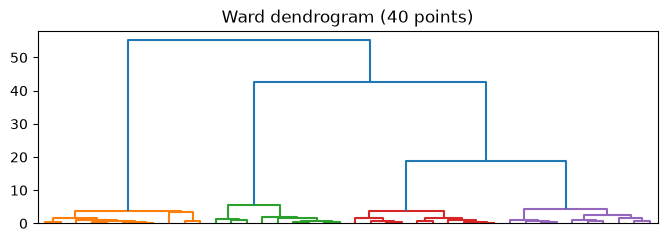

In [15]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
Xh = Xc[:40]                                   # a small sample keeps the dendrogram readable
Z = linkage(Xh, method="ward")
print("cluster sizes when cut into 4 groups:", np.bincount(fcluster(Z, t=4, criterion="maxclust"))[1:])
plt.figure(figsize=(8, 2.5)); dendrogram(Z, no_labels=True, color_threshold=Z[-3, 2]); plt.title("Ward dendrogram (40 points)"); plt.show()

### 15. DBSCAN (density-based clustering)

| | |
|---|---|
| **Core idea** | Clusters are dense regions of points; points in sparse regions are labelled **noise**. |
| **Analogy** | Finding groups of people at a party: a group is wherever people stand close together; the person alone by the window belongs to no group. |
| **Formula / intuition** | Two settings: radius $\varepsilon$ and `min_samples`. A **core point** has at least `min_samples` neighbours within $\varepsilon$. Clusters grow by connecting core points that are within $\varepsilon$ of each other, plus their border points. Everything else is noise (label -1). |
| **Strengths** | finds clusters of any shape, finds the number of clusters itself, flags outliers |
| **Weaknesses** | hard to choose $\varepsilon$ (try a k-distance plot); struggles when clusters have very different densities (HDBSCAN helps); needs scaling |
| **Typical uses** | geographic hot spots (GPS points), anomaly detection, odd-shaped clusters, cleaning noisy data |
| **Go deeper** | [01_clustering](02_unsupervised/01_clustering.ipynb), [clustering and manifold learning in depth](02_unsupervised/05_clustering_and_manifold_learning_in_depth.ipynb) |

In [16]:
from sklearn.cluster import DBSCAN
Xmo, ymo = make_moons(n_samples=400, noise=0.06, random_state=SEED)
Xmo = np.vstack([Xmo, rng.uniform(-1.5, 2.5, size=(15, 2))])          # add 15 random noise points
db = DBSCAN(eps=0.2, min_samples=5).fit(Xmo)
km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(Xmo)
print(f"DBSCAN found {len(set(db.labels_) - {-1})} clusters and {np.sum(db.labels_ == -1)} noise points")
print(f"agreement with the true moons (ARI, 1 = perfect): DBSCAN {adjusted_rand_score(ymo, db.labels_[:400]):.2f}, k-means {adjusted_rand_score(ymo, km.labels_[:400]):.2f}")

DBSCAN found 2 clusters and 11 noise points
agreement with the true moons (ARI, 1 = perfect): DBSCAN 1.00, k-means 0.23


### 16. PCA (principal component analysis)

| | |
|---|---|
| **Core idea** | Rotate the data onto a few new axes that keep as much of the variation as possible. |
| **Analogy** | Photographing a 3D object from the angle that shows the most detail; a flat photo, but you still recognise it. |
| **Formula / intuition** | Centre the data, then find the directions (principal components) of largest variance: the top eigenvectors of the covariance matrix, computed with the SVD. Keep the first $m$ components. The **explained variance ratio** tells you how much information each keeps. |
| **Strengths** | fast, deterministic, removes correlated and redundant features, reduces noise, can be applied to new data, invertible (approximately) |
| **Weaknesses** | only linear structure; components can be hard to interpret; needs scaling when features have different units; variance is not always what matters for prediction |
| **Typical uses** | compressing features before another model, visualising high-dimensional data, denoising, speeding up training |
| **Go deeper** | [02_dimensionality_reduction](02_unsupervised/02_dimensionality_reduction.ipynb) |

In [17]:
from sklearn.decomposition import PCA
Xg, yg = load_digits(return_X_y=True)            # 8x8 images = 64 features
pca = PCA().fit(Xg)
cum = np.cumsum(pca.explained_variance_ratio_)
for m in [2, 10, 20, 40]:
    print(f"{m:>2} components keep {cum[m - 1]:.0%} of the variance (out of 64 features)")

 2 components keep 29% of the variance (out of 64 features)
10 components keep 74% of the variance (out of 64 features)
20 components keep 89% of the variance (out of 64 features)
40 components keep 99% of the variance (out of 64 features)


### 17. t-SNE (t-distributed stochastic neighbour embedding)

| | |
|---|---|
| **Core idea** | Draw high-dimensional points on a 2D map so that points that are neighbours in the original space stay neighbours on the map. |
| **Analogy** | Arranging guests at a wedding so friends sit together; the distance between far-apart tables means little. |
| **Formula / intuition** | Turn distances into \"neighbour probabilities\" in the original space (Gaussian) and on the map (a heavy-tailed t-distribution), then move the map points to make the two sets of probabilities match (minimise KL divergence). **Perplexity** (about 5-50) sets how many neighbours each point cares about. |
| **Strengths** | beautiful, revealing 2D pictures of clusters in complex data (images, embeddings) |
| **Weaknesses** | **for visualisation only**: slow on large data, random (different runs differ), cluster sizes and distances between clusters on the map are not meaningful, can't map new points; UMAP is a faster alternative |
| **Typical uses** | exploring embeddings, checking whether classes separate, presenting cluster structure |
| **Go deeper** | [02_dimensionality_reduction](02_unsupervised/02_dimensionality_reduction.ipynb), [clustering and manifold learning in depth](02_unsupervised/05_clustering_and_manifold_learning_in_depth.ipynb) |

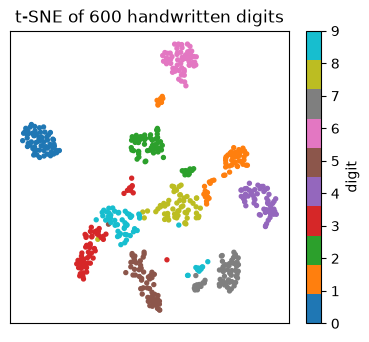

In [18]:
from sklearn.manifold import TSNE
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Xg[:600])
plt.figure(figsize=(4.5, 3.8))
sc = plt.scatter(emb[:, 0], emb[:, 1], c=yg[:600], cmap="tab10", s=8)
plt.colorbar(sc, label="digit"); plt.title("t-SNE of 600 handwritten digits"); plt.xticks([]); plt.yticks([]); plt.show()

## 3. Neural networks

### 18. Neural network (multi-layer perceptron, MLP)

| | |
|---|---|
| **Core idea** | Stack layers of simple units; each layer computes weighted sums of the previous layer and applies a non-linear function. |
| **Analogy** | A team of people passing notes: each person combines the notes they receive in their own way, and after a few rounds the last person gives the answer. |
| **Formula / intuition** | Layer: $h = f(Wx + b)$ with a non-linearity $f$ such as ReLU ($\max(0, z)$). Stack a few layers; the last one outputs the prediction. Train all weights with **backpropagation** (the chain rule computes how each weight affects the loss) and gradient descent. |
| **Strengths** | can learn almost any function given enough data, very flexible, the base of all deep learning |
| **Weaknesses** | needs more data and tuning (layers, learning rate, regularisation); needs scaled inputs; black box; on small tabular data usually **not** better than gradient boosting |
| **Typical uses** | the head of larger deep models, tabular problems with lots of data, embeddings, function approximation |
| **Go deeper** | [neural network fundamentals](../05_Deep_Learning/01_neural_network_fundamentals.ipynb), [neural networks from scratch in NumPy](../05_Deep_Learning/18_neural_networks_from_scratch_numpy.ipynb) |

In [19]:
from sklearn.neural_network import MLPClassifier
Xtr, Xte, ytr, yte = split(Xm, ym)
mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=SEED)).fit(Xtr, ytr)
print(f"MLP accuracy on the curved moons data = {accuracy_score(yte, mlp.predict(Xte)):.3f}")
print("weights per layer:", [w.shape for w in mlp[-1].coefs_])

MLP accuracy on the curved moons data = 0.893
weights per layer: [(2, 32), (32, 16), (16, 1)]


### 19. Convolutional neural network (CNN)

| | |
|---|---|
| **Core idea** | Slide small learned filters over an image to detect local patterns, then combine them into bigger patterns layer by layer. |
| **Analogy** | Scanning a page with a magnifying glass that lights up whenever it sees a particular stroke; later glasses look for combinations of strokes. |
| **Formula / intuition** | A **convolution** computes, at every position, the sum of (filter weights $\times$ the pixels under the filter). The same small filter is reused everywhere (**weight sharing**), so the model needs few parameters and finds a pattern wherever it appears. Then ReLU, then **pooling** (keep the max in each small window) to shrink the map. Early layers find edges; later layers find shapes and objects. |
| **Strengths** | state of the art for many vision tasks, efficient for grid-like data, built-in tolerance to shifts |
| **Weaknesses** | needs a lot of labelled data (or a pretrained model to fine-tune) and usually a GPU; vision transformers now compete at large scale |
| **Typical uses** | image classification, object detection, medical imaging, audio spectrograms, some time series |
| **Go deeper** | [CNNs](../05_Deep_Learning/03_cnn.ipynb), [computer vision](../06_Computer_Vision/) |

In [20]:
img = np.zeros((6, 6)); img[:, 3:] = 1.0                     # a tiny image: dark left half, bright right half
kernel = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])     # a vertical-edge detector (learned in a real CNN)
conv = np.array([[np.sum(img[i:i+3, j:j+3] * kernel) for j in range(4)] for i in range(4)])
relu = np.maximum(conv, 0)
pooled = relu.reshape(2, 2, 2, 2).max(axis=(1, 3))           # 2x2 max pooling
print("feature map after conv + ReLU (lights up at the edge):\n", relu, "\nafter 2x2 max pooling:\n", pooled)

feature map after conv + ReLU (lights up at the edge):
 [[0. 3. 3. 0.]
 [0. 3. 3. 0.]
 [0. 3. 3. 0.]
 [0. 3. 3. 0.]] 
after 2x2 max pooling:
 [[3. 3.]
 [3. 3.]]


### 20. Recurrent neural network (RNN / LSTM)

| | |
|---|---|
| **Core idea** | Read a sequence one step at a time while carrying a **hidden state**, a memory of what came before. |
| **Analogy** | Reading a sentence word by word and keeping a running mental summary. |
| **Formula / intuition** | Simple RNN: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$, the same weights at every step. Plain RNNs forget long-range information (gradients vanish). An **LSTM** adds a memory cell and three **gates** (forget, input, output: small sigmoid layers that decide what to erase, write and read), so it can remember over longer spans. A GRU is a simpler gated variant. |
| **Strengths** | natural for sequences of any length, small and fast at inference, still good for streaming signals |
| **Weaknesses** | slow to train (steps can't be parallelised), limited long-range memory; **transformers** have replaced them for most language tasks |
| **Typical uses** | time series forecasting, sensor and streaming data, speech, small on-device sequence models |
| **Go deeper** | [RNN, LSTM, GRU](../05_Deep_Learning/04_rnn_lstm_gru.ipynb), [sequence models hands-on](../05_Deep_Learning/19_sequence_models_hands_on.ipynb) |

In [21]:
r_ = np.random.default_rng(0)
W_x, W_h, b = r_.normal(0, 0.5, (3, 1)), r_.normal(0, 0.5, (3, 3)), np.zeros(3)   # 1 input -> 3 hidden units
sequence = [1.0, 0.0, 0.0, 0.0, 0.0]                       # a single "blip" at the start
h = np.zeros(3)
for t, x_t in enumerate(sequence):
    h = np.tanh(W_x @ [x_t] + W_h @ h + b)                 # same weights reused at every time step
    print(f"t={t} input={x_t}  hidden state={h.round(3)}")
print("The blip at t=0 still echoes in the hidden state later (memory), and slowly fades.")

t=0 input=1.0  hidden state=[ 0.063 -0.066  0.31 ]
t=1 input=0.0  hidden state=[ 0.077 -0.099 -0.013]
t=2 input=0.0  hidden state=[ 0.028  0.008 -0.018]
t=3 input=0.0  hidden state=[-0.004  0.028 -0.021]
t=4 input=0.0  hidden state=[-0.012  0.018 -0.007]
The blip at t=0 still echoes in the hidden state later (memory), and slowly fades.


## 4. Reinforcement learning

### 21. Q-learning

| | |
|---|---|
| **Core idea** | Learn, by trial and error, a table of how good each action is in each situation, then pick the best action. |
| **Analogy** | Learning to find your way through a new city: you remember which turns eventually led somewhere good, and update that memory each trip. |
| **Formula / intuition** | Keep a table $Q(s, a)$ = expected future reward of doing action $a$ in state $s$. After each step: $Q(s,a) \leftarrow Q(s,a) + \alpha \,[\, r + \gamma \max_{a'} Q(s', a') - Q(s,a) \,]$ ($\alpha$ = learning rate, $\gamma$ = how much future rewards count). Explore with **epsilon-greedy**: usually take the best action, sometimes a random one. |
| **Strengths** | simple, learns without a model of the environment, provably converges in small tabular problems (with enough exploration) |
| **Weaknesses** | the table explodes for large or continuous state spaces (use deep Q-networks); needs many trials; reward design is tricky |
| **Typical uses** | games, simple robot or control tasks, inventory and pricing simulations, teaching RL |
| **Go deeper** | [Monte Carlo and TD](../11_Reinforcement_Learning/03_monte_carlo_td.ipynb), [tabular RL from scratch](../11_Reinforcement_Learning/09_tabular_rl_from_scratch.ipynb), [deep Q-networks](../11_Reinforcement_Learning/04_deep_q_networks.ipynb) |

In [22]:
# 4x4 gridworld: start top-left (S), goal bottom-right (G, +10), a pit (X, -10), every step costs -1.
N, GOAL, PIT, ACTIONS = 4, (3, 3), (1, 2), {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}   # up, down, left, right
Q, r_ = np.zeros((N, N, 4)), np.random.default_rng(1)
for episode in range(800):
    s = (0, 0)
    for _ in range(50):
        a = int(r_.integers(4)) if r_.random() < 0.2 else int(Q[s].argmax())        # epsilon-greedy
        s2 = (min(max(s[0] + ACTIONS[a][0], 0), N - 1), min(max(s[1] + ACTIONS[a][1], 0), N - 1))
        reward = 10 if s2 == GOAL else -10 if s2 == PIT else -1
        Q[s][a] += 0.1 * (reward + 0.95 * Q[s2].max() * (s2 not in (GOAL, PIT)) - Q[s][a])
        s = s2
        if s in (GOAL, PIT):
            break
arrows = np.array(["^", "v", "<", ">"])[Q.argmax(axis=2)]
arrows[GOAL], arrows[PIT] = "G", "X"
print("learned policy (best action in each cell):"); print("\n".join(" ".join(row) for row in arrows))

learned policy (best action in each cell):
v v < v
> v X v
> v v v
> > > G


**What just happened?** Starting with a table of zeros, the agent wandered, fell into the pit sometimes, and reached the goal sometimes. Each update pushed the value of "good" moves up and "bad" moves down, and the arrows now lead from the start to G while steering around the pit X. (Cells the agent rarely visits may still show odd arrows; that is normal with little exploration.)

## 5. How to choose: a flowchart

```mermaid
flowchart TD
    A{Do you have labels<br/>the right answers?} -->|no| U{What do you want?}
    A -->|"no labels, but rewards<br/>from acting"| RL[Q-learning / RL]
    A -->|yes| D{What kind of data?}
    U -->|groups| G{Know how many<br/>and roughly round?}
    G -->|yes| KM[k-means]
    G -->|"odd shapes, noise"| DB[DBSCAN]
    G -->|"want a hierarchy,<br/>small data"| HC[hierarchical]
    U -->|"fewer features /<br/>compression"| PCA[PCA]
    U -->|"a 2D picture only"| TS[t-SNE]
    D -->|images| CNN[CNN or pretrained vision model]
    D -->|"sequences / text"| SEQ["RNN/LSTM for small streaming data;<br/>transformers for language"]
    D -->|"tabular: rows and columns"| T{Predict a number<br/>or a category?}
    T -->|number| R["Baseline: mean / last value<br/>then linear regression<br/>then gradient boosting / random forest"]
    T -->|category| CL["Baseline: majority class<br/>then logistic regression<br/>then gradient boosting / random forest"]
    CL --> SP{Special case?}
    SP -->|"text, tiny data"| NB[naive Bayes]
    SP -->|"small, many features"| SVM[SVM]
    SP -->|"Gaussian-looking classes"| LQ[LDA / QDA]
    SP -->|"need plain rules"| DT[decision tree]
    SP -->|"lots of data"| MLP[MLP]
```

| If you need... | Try first | Then |
|---|---|---|
| a baseline for anything | majority class / mean / last value | logistic or linear regression |
| the best accuracy on tabular data | gradient boosting (HistGradientBoosting, XGBoost, LightGBM) | random forest, then tune |
| an explanation a regulator can read | logistic regression, small decision tree | explainability tools on a stronger model ([explainability](07_explainability/01_explainability.ipynb)) |
| text classification with little data | naive Bayes or logistic regression on TF-IDF | fine-tuned small transformer |
| groups without labels | k-means (check silhouette) | DBSCAN or hierarchical for odd shapes |
| a picture of high-dimensional data | PCA (fast, reusable) | t-SNE or UMAP (visual only) |
| images | pretrained CNN, fine-tuned | train a CNN from scratch only with lots of data |
| decisions from trial and error | Q-learning (small problems) | deep RL ([RL notebooks](../11_Reinforcement_Learning/01_rl_fundamentals.ipynb)) |

## 6. Benchmark: 12 classifiers, 3 datasets, 5-fold cross-validation

**What it is.** **Cross-validation** splits the data into 5 parts, trains on 4 and tests on the 5th, five times, and averages. It gives a fairer score than one split and shows how much the score wobbles.

**Rules for a fair comparison:** the same folds for every model, scaling inside the pipeline (so the test fold never leaks into the scaler), and default or lightly chosen settings for everyone. The **dummy** model (always predicts the most common class) is the floor every model must beat.

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
scaled = lambda m: make_pipeline(StandardScaler(), m)
MODELS = {
    "dummy (majority class)": DummyClassifier(strategy="most_frequent"),
    "logistic regression": scaled(LogisticRegression(max_iter=2000)),
    "KNN (k=5)": scaled(KNeighborsClassifier(5)),
    "Gaussian naive Bayes": GaussianNB(),
    "decision tree": DecisionTreeClassifier(random_state=SEED),
    "random forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=SEED),
    "gradient boosting (hist)": HistGradientBoostingClassifier(random_state=SEED),
    "SVM (RBF)": scaled(SVC()),
    "LDA": LinearDiscriminantAnalysis(),
    "QDA (reg 0.1)": QuadraticDiscriminantAnalysis(reg_param=0.1),
    "MLP": scaled(MLPClassifier(hidden_layer_sizes=(64,), max_iter=2000, random_state=SEED)),
}
DATASETS = {"breast cancer": (Xb, yb), "wine": (Xw, yw), "moons (noisy)": (Xm, ym)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

results, start = {}, time.time()
for dname, (X, y) in DATASETS.items():
    for mname, model in MODELS.items():
        s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
        results[(mname, dname)] = (s.mean(), s.std())
print(f"ran {len(MODELS) * len(DATASETS) * 5} fits in {time.time() - start:.1f}s")

table = pd.DataFrame({d: {m: f"{results[(m, d)][0]:.3f} ± {results[(m, d)][1]:.3f}" for m in MODELS} for d in DATASETS})
means = pd.DataFrame({d: {m: results[(m, d)][0] for m in MODELS} for d in DATASETS})
table["average rank"] = means.rank(ascending=False).mean(axis=1).round(1)
print(table.sort_values("average rank").to_string())

ran 180 fits in 18.3s
                          breast cancer           wine  moons (noisy)  average rank
SVM (RBF)                 0.977 ± 0.016  0.983 ± 0.022  0.905 ± 0.028           2.2
MLP                       0.982 ± 0.008  0.989 ± 0.014  0.898 ± 0.027           2.3
logistic regression       0.974 ± 0.017  0.983 ± 0.014  0.848 ± 0.033           4.7
KNN (k=5)                 0.963 ± 0.018  0.972 ± 0.018  0.905 ± 0.028           5.2
random forest             0.954 ± 0.010  0.977 ± 0.021  0.902 ± 0.028           6.0
AdaBoost                  0.967 ± 0.015  0.927 ± 0.046  0.900 ± 0.030           6.2
gradient boosting (hist)  0.967 ± 0.013  0.966 ± 0.033  0.893 ± 0.039           6.5
LDA                       0.956 ± 0.020  0.983 ± 0.014  0.845 ± 0.030           7.2
QDA (reg 0.1)             0.956 ± 0.006  0.983 ± 0.022  0.840 ± 0.027           7.3
Gaussian naive Bayes      0.939 ± 0.023  0.972 ± 0.025  0.845 ± 0.030           8.8
decision tree             0.910 ± 0.028  0.893 ± 0.038

**How to read this table.**
- Every real model beats the dummy by a wide margin, so the floor check passes.
- On these small, clean datasets, **several models are within about one standard deviation of each other**. Differences that small are mostly noise from the particular folds; don't crown a winner from them.
- Linear models (logistic regression, LDA) are excellent on breast cancer and wine, which are close to linearly separable. On the curved **moons** data they fall behind, and models that can bend (SVM with RBF kernel, KNN, MLP, boosting, forests) win.
- A single decision tree is usually near the bottom: that is exactly why forests and boosting exist.
- Results depend on the data. On large, messy, real tabular data, gradient boosting is usually the strongest default; on these toy sets it doesn't have to be. Always benchmark on **your** data, with the **same folds** for all models.

## 7. Start with a simple baseline

The most-repeated advice from experienced practitioners: **before anything fancy, build the simplest reasonable model**, and only keep a complex model if it beats the baseline by a margin that matters. A baseline tells you whether the problem is easy, whether your pipeline has bugs (a fancy model doing *worse* than the baseline is a red flag), and how much the fancy model really adds.

| Task | Baseline |
|---|---|
| classification | majority class, then logistic regression |
| regression | predict the mean (or median), then linear regression |
| forecasting | **naive "last value"** (tomorrow = today), **seasonal naive** (next Monday = last Monday) |
| ranking / recommendations | most popular items |
| text | keyword rules, then naive Bayes or logistic regression on TF-IDF |

Below: regression on the diabetes data, and a forecasting example.

In [24]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
for name, model in [("predict the mean", DummyRegressor()), ("linear regression", LinearRegression()),
                    ("gradient boosting", GradientBoostingRegressor(random_state=SEED))]:
    mae = -cross_val_score(model, Xd, yd, cv=5, scoring="neg_mean_absolute_error").mean()   # 5-fold CV
    print(f"{name:20} MAE = {mae:5.1f}")
print("-> the plain linear model is as good as (here: better than) default gradient boosting on this small dataset")

predict the mean     MAE =  66.0
linear regression    MAE =  44.3


gradient boosting    MAE =  46.8
-> the plain linear model is as good as (here: better than) default gradient boosting on this small dataset


In [25]:
# Forecasting: daily sales = slowly wandering level + weekly pattern + noise (synthetic, illustrative)
days = 400
level = 100 + np.cumsum(rng.normal(0, 2, days))                     # random-walk level
weekly = 10 * np.sin(2 * np.pi * np.arange(days) / 7)
sales = level + weekly + rng.normal(0, 3, days)
test = np.arange(300, days)                                         # forecast each of the last 100 days, one day ahead

naive = sales[test - 1]                                             # tomorrow = today
seasonal_naive = sales[test - 7]                                    # tomorrow = same weekday last week
lags = np.column_stack([np.roll(sales, k) for k in range(1, 15)])   # features: the previous 14 days
gb = GradientBoostingRegressor(random_state=SEED).fit(lags[14:300], sales[14:300])
gb_pred = gb.predict(lags[test])
lr = LinearRegression().fit(lags[14:300], sales[14:300])
lr_pred = lr.predict(lags[test])

for name, pred in [("naive (last value)", naive), ("seasonal naive (last week)", seasonal_naive),
                   ("linear regression on 14 lags", lr_pred), ("gradient boosting on 14 lags", gb_pred)]:
    print(f"{name:30} MAE = {mean_absolute_error(sales[test], pred):5.2f}")

naive (last value)             MAE =  6.25
seasonal naive (last week)     MAE =  5.26
linear regression on 14 lags   MAE =  3.33
gradient boosting on 14 lags   MAE = 21.11


**What just happened?** On the diabetes data, default gradient boosting did **not** beat plain linear regression: with 442 rows and a mostly linear signal, the simple model is enough. In the forecasting example, the naive forecasts are cheap and already decent; the lag-based linear model wins because it can combine "yesterday" and "same day last week". The tree model does worse here because a wandering level drifts outside the range it saw in training, and trees cannot extrapolate (see the KNN regression card). Without the baselines you would not know any of this. Deeper forecasting practice: [forecasting done right](../04_Forecasting/00_start_here_forecasting_done_right.ipynb).

## 8. Recap cheat sheet

| # | Algorithm | One-line idea | Scale features? | Non-linear? | Interpretable? | Go deeper |
|---|---|---|---|---|---|---|
| 1 | Linear regression | weighted sum, least squares | helps (for regularisation) | no | high | [link](01_supervised/01_linear_regression.ipynb) |
| 2 | Logistic regression | weighted sum through a sigmoid | yes | no | high | [link](01_supervised/02_logistic_regression.ipynb) |
| 3 | KNN | vote of nearest neighbours | **yes** | yes | medium | [link](01_supervised/07_knn.ipynb) |
| 4 | KNN regression | average of nearest neighbours | **yes** | yes | medium | [link](01_supervised/07_knn.ipynb) |
| 5 | Naive Bayes | Bayes' rule + independence | no | limited | medium | [link](01_supervised/06_naive_bayes.ipynb) |
| 6 | Decision tree | flowchart of yes/no splits | no | yes | high (if small) | [link](01_supervised/03_decision_trees.ipynb) |
| 7 | Random forest | average of randomised trees | no | yes | low-medium | [link](01_supervised/04_ensemble_methods.ipynb) |
| 8 | AdaBoost | reweight mistakes, weighted vote of stumps | no | yes | low-medium | [link](01_supervised/04_ensemble_methods.ipynb) |
| 9 | Gradient boosting | trees fitted to remaining errors | no | yes | low-medium | [link](01_supervised/04_ensemble_methods.ipynb) |
| 10 | SVM | widest-margin boundary, kernels | **yes** | with kernels | low | [link](01_supervised/05_svm.ipynb) |
| 11 | LDA | Gaussian classes, shared shape | no | no | medium | [link](01_supervised/08_generalized_linear_models.ipynb) |
| 12 | QDA | Gaussian classes, own shapes | no | quadratic | medium | [link](01_supervised/08_generalized_linear_models.ipynb) |
| 13 | K-means | k centres, nearest-centre groups | **yes** | no (round clusters) | high | [link](02_unsupervised/01_clustering.ipynb) |
| 14 | Hierarchical | merge closest clusters, dendrogram | **yes** | depends on linkage | high | [link](02_unsupervised/01_clustering.ipynb) |
| 15 | DBSCAN | dense regions, noise points | **yes** | yes | medium | [link](02_unsupervised/01_clustering.ipynb) |
| 16 | PCA | rotate to max-variance axes | **yes** | no | medium | [link](02_unsupervised/02_dimensionality_reduction.ipynb) |
| 17 | t-SNE | keep neighbours together on a 2D map | yes | yes | visual only | [link](02_unsupervised/02_dimensionality_reduction.ipynb) |
| 18 | MLP | stacked layers + backprop | **yes** | yes | low | [link](../05_Deep_Learning/01_neural_network_fundamentals.ipynb) |
| 19 | CNN | sliding learned filters | normalise pixels | yes | low | [link](../05_Deep_Learning/03_cnn.ipynb) |
| 20 | RNN / LSTM | hidden state carried over time | yes | yes | low | [link](../05_Deep_Learning/04_rnn_lstm_gru.ipynb) |
| 21 | Q-learning | table of action values from trial and error | - | - | high (small tables) | [link](../11_Reinforcement_Learning/09_tabular_rl_from_scratch.ipynb) |

## 9. Interview questions

1. **Random forest vs gradient boosting?** Forests train independent deep trees in parallel and average them (lower variance); boosting trains shallow trees one after another, each fixing the remaining errors (lower bias). Boosting is usually more accurate when tuned, forests are more robust with defaults.
2. **Why scale features for KNN, SVM and neural networks but not for trees?** The first three use distances or gradient steps, so a feature measured in thousands dominates one measured in decimals. Trees only compare a feature with a threshold, so the scale doesn't matter.
3. **Why is naive Bayes "naive", and why does it still work?** It assumes features are independent given the class, which is rarely true. The class ranking is often still right even when the probabilities are off, especially for text.
4. **LDA vs QDA?** LDA assumes all classes share one covariance, giving linear boundaries and needing less data. QDA gives each class its own covariance, giving curved boundaries but needing more data.
5. **k-means vs DBSCAN?** k-means needs k and finds round clusters; DBSCAN finds the number of clusters itself, handles odd shapes and flags noise, but needs a good radius and struggles with mixed densities.
6. **PCA vs t-SNE?** PCA is linear, fast, deterministic and can transform new data (good for preprocessing). t-SNE is non-linear and for visualisation only; distances between clusters on a t-SNE map mean little.
7. **What does AdaBoost do with misclassified points?** Increases their weights so the next weak learner focuses on them; the final prediction is a weighted vote.
8. **Why did LSTMs replace simple RNNs, and what replaced LSTMs?** Gates let LSTMs keep information over longer spans (fewer vanishing gradients). Transformers replaced them for most language tasks because attention is parallel and handles long context better.
9. **What is the Q-learning update in words?** Move the current estimate a little toward "reward now plus the discounted best value of the next state".
10. **Why start with a baseline?** It shows how hard the problem is, catches pipeline bugs, and tells you whether the complex model is worth its cost.

## Further reading

- G. James, D. Witten, T. Hastie and R. Tibshirani, *An Introduction to Statistical Learning* (2nd ed., 2021; free online).
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning* (2nd ed., 2009; free online).
- scikit-learn user guide, and its "Choosing the right estimator" map.
- L. Breiman, "Random Forests", *Machine Learning*, 2001.
- Y. Freund and R. Schapire, "A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting", 1997 (AdaBoost).
- J. Friedman, "Greedy Function Approximation: A Gradient Boosting Machine", *Annals of Statistics*, 2001.
- T. Chen and C. Guestrin, "XGBoost: A Scalable Tree Boosting System", KDD 2016 (arXiv:1603.02754); G. Ke et al., "LightGBM: A Highly Efficient Gradient Boosting Decision Tree", NeurIPS 2017.
- C. Cortes and V. Vapnik, "Support-Vector Networks", *Machine Learning*, 1995.
- M. Ester, H.-P. Kriegel, J. Sander and X. Xu, "A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise", KDD 1996 (DBSCAN).
- L. van der Maaten and G. Hinton, "Visualizing Data using t-SNE", *JMLR*, 2008.
- Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, "Gradient-Based Learning Applied to Document Recognition", 1998 (CNNs).
- S. Hochreiter and J. Schmidhuber, "Long Short-Term Memory", *Neural Computation*, 1997.
- C. Watkins and P. Dayan, "Q-learning", *Machine Learning*, 1992; R. Sutton and A. Barto, *Reinforcement Learning: An Introduction* (2nd ed., 2018).
- L. Grinsztajn, E. Oyallon and G. Varoquaux, "Why do tree-based models still outperform deep learning on tabular data?", NeurIPS 2022 Datasets and Benchmarks (arXiv:2207.08815).
- R. Hyndman and G. Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed., free online): simple forecasting baselines.